In [21]:
import re
import ast
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

In [24]:
data = pd.read_excel('data/Annotated Data/o4mini_annotation_final.xlsx', sheet_name='data2')
data.head()

,vaers_id,symptom_text,symptom_list,llm_result,llm_result_formatted,t_result,t_corrected_version,t_category,t_notes,h_result,...,h_notes,final_result,final_corrected_version,final_notes,all_symptoms_extracted,missing_symptoms,llm_errors,num_groups,agreement,text_length
0,1420769,"About 4-5 days after my second dose, I began h...","['Chest discomfort', 'Chest pain', 'Electrocar...","[ \n { \n ""Chest pain"": [""non stop chest...","[\n {\n ""Chest pain"": [\n ""non stop c...",1,NaN,NaN,NaN,1,...,NaN,1,NaN,NaN,True,NaN,NaN,4.0,True,110
1,1527339,"cough, nasal congestion, runny nose, cold swea...","['Cold sweat', 'Cough', 'Fatigue', 'Hypogeusia...","""No temporal information found""",No temporal information found,1,NaN,NaN,NaN,1,...,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,True,18
2,1831772,"Muscle pain, headache, nausea. Muscle pain ins...","['Headache', 'Immediate post-injection reactio...","[\n {\n ""Headache"": [""none""],\n ""Immedi...","[\n {\n ""Myalgia"": [\n ""Muscle pain""\...",0,"[\n {\n ""Myalgia"": [\n ""Muscle pain""\...",Symptoms with no original mention should be gr...,NaN,0,...,format,0,"[\n {\n ""Myalgia"": [\n ""Muscle pain""\...",LLM formatting issue; incorrect grouping; miss...,True,NaN,NaN,2.0,False,13
3,1021935,back pain/soreness in his lower back/had bad l...,"['Arthralgia', 'Back pain', 'Nausea', 'Pain in...","[\n {\n ""Vaccination site pain"": [""injecti...","[\n {\n ""Vaccination site pain"": [\n ...",1,NaN,NaN,NaN,0,...,Wrong order.,1,NaN,NaN,True,NaN,NaN,2.0,False,260
4,2749020,The above vaccines administered without incide...,"['Dizziness', 'Fall', 'Fatigue', 'Head injury'...","[\n {\n ""Syncope"": [""patient fainted""],\n ...","[\n {\n ""Syncope"": [\n ""patient faint...",1,NaN,NaN,NaN,1,...,NaN,1,NaN,NaN,True,NaN,NaN,2.0,True,118


In [26]:
def llm_result_final(row):
    result = None
    if int(row.final_result) in [0, 1]:
        if pd.isna(row.final_corrected_version):
            result = row.llm_result_formatted
        else:
            result = row.final_corrected_version

    return result

def replace_substrings(text):

    mapping = {
        'llm format issue': 'llm formatting issue',
        'incorrect original mentions': 'incorrect original mention',
        'incorrect original mentions and symptom grouping': 'incorrect original mention; incorrect grouping',
        'symptoms groups are partially incorrect': 'incorrect grouping',
        'missing symptoms (pain)': 'missing symptoms',
        'original mention missing': 'missing original mention',
        'wrong original mention': 'incorrect original mention',
        'symptoms are repeated': 'repeated symptoms',
        'missing original symptoms': 'missing symptoms',
        'llm formatting issue/format; wrong mention; pain': 'llm formatting issue; incorrect original mention; pain',
        'symptom repitition': 'repeated symptoms'
    }
    if pd.isna(text):
        return text  # handle NaN safely
    for key, value in mapping.items():
        if key in text:
            text = text.replace(key, value)
    return text

def extract_errors(text):
    """Extract individual issues from the notes, handling various separators"""
    if pd.isna(text) or text == '':
        return []

    # Split by common separators: ; and .
    errors = re.split(r'[;.]', str(text))

    # Clean up each issue
    errors_list = []
    for error in errors:
        error = error.strip()
        if error and error not in ['', ' ']:
            # Remove trailing punctuation and normalize whitespace
            error = re.sub(r'\s+', ' ', error)
            errors_list.append(error)

    return errors_list

In [27]:
data['llm_result_final'] = data.apply(llm_result_final, axis=1)
data['final_notes'] = data['final_notes'].apply(lambda x: x.strip().lower() if isinstance(x, str) else x)
data['final_notes'] = data['final_notes'].apply(replace_substrings)
data['issues'] = data['final_notes'].apply(extract_errors)
data['llm_a1_agreement'] = data.apply(lambda row: row.t_result == 1, axis=1)
data['llm_a2_agreement'] = data.apply(lambda row: row.h_result == 1, axis=1)
data['a1_a2_agreement'] = data.apply(lambda row: row.t_result == row.h_result, axis=1)
data['llm_final_agreement'] = data.apply(lambda row: row.final_result == 1, axis=1)

In [28]:
no_temporal_records = data.query('final_corrected_version == "No temporal information found"')
uncertain_records = data.query('final_result == 2')
incorrect_records = data.query('final_result == 0')
data_to_analyze = data.query('final_result != 2 and llm_result_final != "No temporal information found"')
data_to_analyze.shape

(3166, 23)

In [29]:
columns = [
    'vaers_id', 'symptom_text', 'symptom_list',
    'llm_result_formatted', 't_result', 'h_result', 'final_result',
    'final_corrected_version', 'final_notes', 'all_symptoms_extracted',
    'missing_symptoms', 'llm_errors', 'num_groups', 'agreement',
    'text_length', 'llm_result_final', 'issues'
]

## Exploratory Data Analysis:

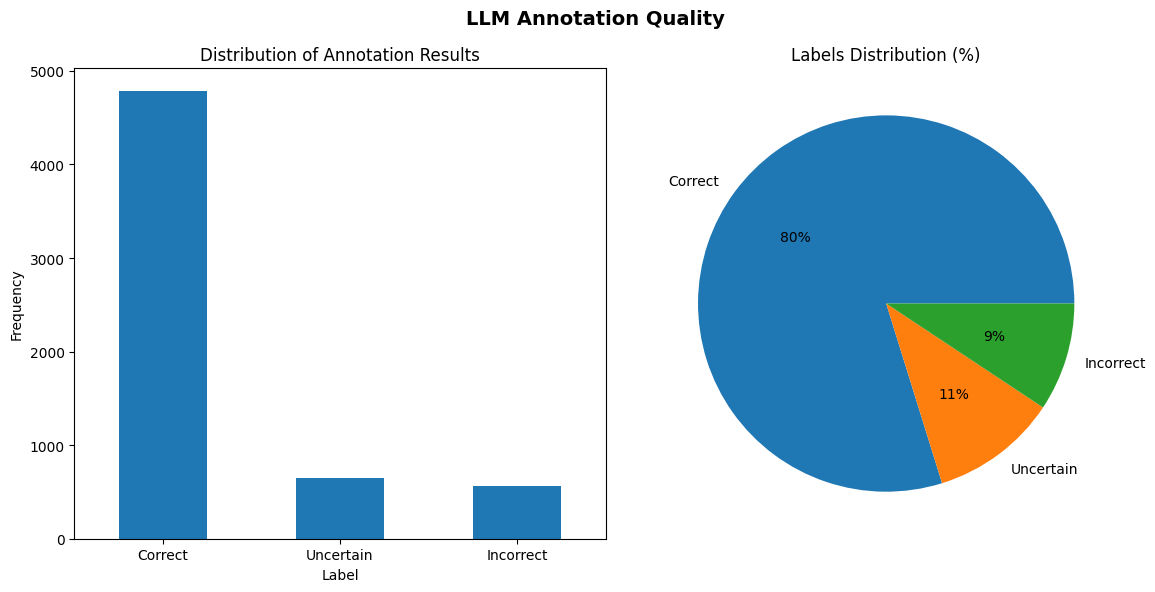

In [68]:
# Map values to labels and get counts
labeled_counts = data.final_result.map({ 0: 'Incorrect', 1: 'Correct', 2: 'Uncertain'}).value_counts()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

labeled_counts.plot.bar(ax=ax1)
ax1.set_xlabel('Label')
ax1.set_ylabel('Frequency')
ax1.tick_params(axis='x', rotation=0)
ax1.set_title('Distribution of Annotation Results')

# Pie chart on right
labeled_counts.plot.pie(autopct='%1.0f%%', ax=ax2)
ax2.set_ylabel('')
ax2.set_title('Labels Distribution (%)')

fig.suptitle('LLM Annotation Quality', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

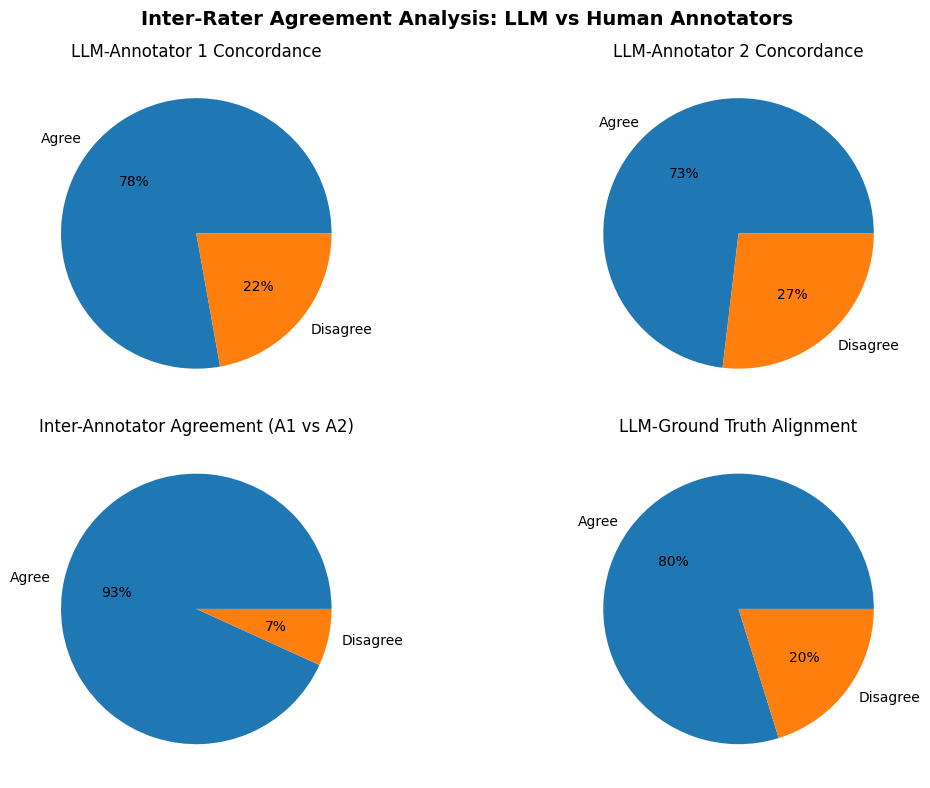

In [70]:
fig, axs = plt.subplots(2, 2, figsize=(12, 8))

agreement_mapping = {True: 'Agree', False: 'Disagree'}
llm_a1_agreement = data.llm_a1_agreement.map(agreement_mapping).value_counts()
llm_a1_agreement.plot.pie(autopct='%1.0f%%', ax=axs[0, 0])
axs[0, 0].set_title('LLM-Annotator 1 Concordance')

llm_a2_agreement = data.llm_a2_agreement.map(agreement_mapping).value_counts()
llm_a2_agreement.plot.pie(autopct='%1.0f%%', ax=axs[0, 1])
axs[0, 1].set_title('LLM-Annotator 2 Concordance')

a1_a2_agreement = data.a1_a2_agreement.map(agreement_mapping).value_counts()
a1_a2_agreement.plot.pie(autopct='%1.0f%%', ax=axs[1, 0])
axs[1, 0].set_title('Inter-Annotator Agreement (A1 vs A2)')

llm_final_agreement = data.llm_final_agreement.map(agreement_mapping).value_counts()
llm_final_agreement.plot.pie(autopct='%1.0f%%', ax=axs[1, 1])
axs[1, 1].set_title('LLM-Ground Truth Alignment')

for ax in axs.flatten():
    ax.set_ylabel('')  # Remove the y-label that pie charts often have

fig.suptitle('Inter-Rater Agreement Analysis: LLM vs Human Annotators', fontsize=14,  fontweight='bold')
plt.tight_layout()
plt.show()

In [31]:
def get_data_issues(data):
    #Create a flat list of all issues
    all_issues = []
    for issues_list in data['issues']:
        all_issues.extend(issues_list)

    # Count frequency of each issue and get top 10
    return Counter(all_issues)


def get_symptoms_count(data, index=0):
    """

    :param data: Dataframe with columns llm_result_final
    :param index: 0 for first group, -1 for last group
    :return:
    """

    symptoms = []
    for record in data.itertuples():
        try:
            if isinstance(record.llm_result_final, str):
                ordered_symptoms_list = ast.literal_eval(record.llm_result_final)
                symptoms.extend(list(ordered_symptoms_list[index].keys()))

        except Exception as e:
            print(record.vaers_id, e)

    symptoms_count = Counter(symptoms)
    return symptoms_count


def get_symptoms_with_no_original_mention(data):

    symptoms_with_no_mention = []
    for record in data.itertuples():
        try:
            if isinstance(record.llm_result_final, str):
                ordered_symptoms_list = ast.literal_eval(record.llm_result_final)
                last_group = ordered_symptoms_list[-1]

                if any(value == ["none"] for value in list(last_group.values())):
                    symptoms_with_no_mention.extend(list(last_group.keys()))

        except Exception as e:
            print(record.vaers_id, e)

    symptoms_with_no_mention = Counter(symptoms_with_no_mention)
    return symptoms_with_no_mention


def get_symptoms_with_missing_original_mention(data):

    all_symptoms_with_missing_mention = []

    for record in data.itertuples():
        try:
            if isinstance(record.llm_result_formatted, str):
                initial_symptoms_list = ast.literal_eval(record.llm_result_formatted)
                initial_symptoms_without_mention = []

                if any(value == ["none"] for value in initial_symptoms_list[-1].values()):
                    initial_symptoms_without_mention = list(initial_symptoms_list[-1].keys())

                if isinstance(record.llm_result_final, str):
                    final_symptoms_list = ast.literal_eval(record.llm_result_final)
                    final_symptoms_without_mention = []

                    if any(value == ["none"] for value in final_symptoms_list[-1].values()):
                        final_symptoms_without_mention = list(final_symptoms_list[-1].keys())

                    symptoms_with_missing_mention = set(initial_symptoms_without_mention) - set(final_symptoms_without_mention)
                    all_symptoms_with_missing_mention.extend(list(symptoms_with_missing_mention))

        except Exception as e:
            print(record.vaers_id, e, record.llm_result_formatted, record.llm_result_final)

    symptoms_with_missing_mention = Counter(all_symptoms_with_missing_mention)
    return symptoms_with_missing_mention


def plot_top(counter, text='Symptoms'):

    top_10 = counter.most_common(10)

    # Create DataFrame for plotting
    top_10_df = pd.DataFrame(top_10, columns=[text, 'Count'])

    # Plotting
    plt.figure(figsize=(12, 8))

    # Create horizontal bar plot (easier to read long issue names)
    plt.subplot(1, 2, 1)
    bars = plt.barh(top_10_df[text], top_10_df['Count'])
    plt.xlabel('Frequency')
    plt.title(f'Top 10 Most Common {text.title()}')
    plt.gca().invert_yaxis()  # Highest count at top

    # Add value labels on bars
    for bar in bars:
        width = bar.get_width()
        plt.text(width + 0.1, bar.get_y() + bar.get_height()/2,
                 f'{int(width)}', ha='left', va='center')

    # Create pie chart for proportion view
    plt.subplot(1, 2, 2)
    plt.pie(top_10_df['Count'], labels=top_10_df[text], autopct='%1.1f%%', startangle=90)
    plt.title(f'Proportion of Top 10 {text.title()}')

    plt.tight_layout()
    plt.show()

    # Print the top 10 issues for reference
    # print(f"\nTop 10 {text.title()}:")
    # for i, (text, count) in enumerate(top_10, 1):
    #     print(f"{i}. {text}: {count} occurrences")

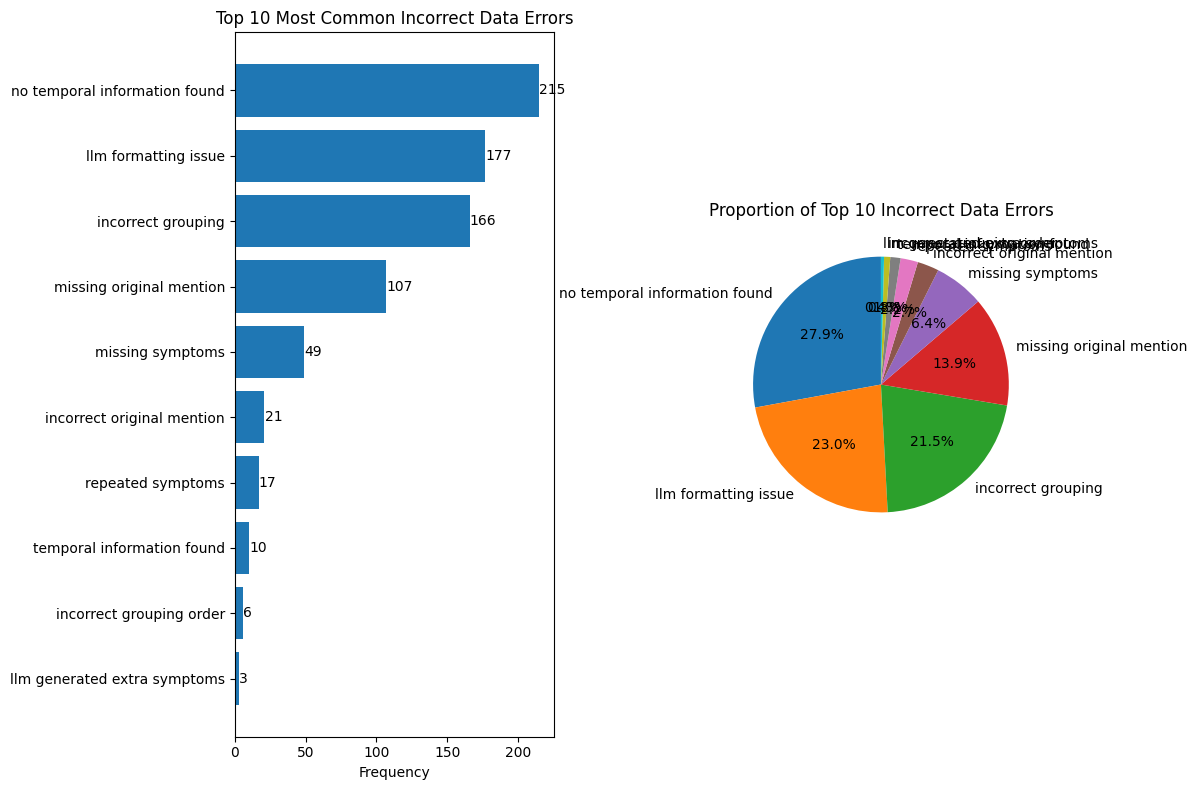

In [32]:
incorrect_data_errors = get_data_issues(incorrect_records)
plot_top(incorrect_data_errors, 'Incorrect Data Errors')

/var/folders/k4/zx_j67kd21n6d03ptwmp8_vm0000gn/T/ipykernel_15241/993889114.py:110: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  plt.tight_layout()


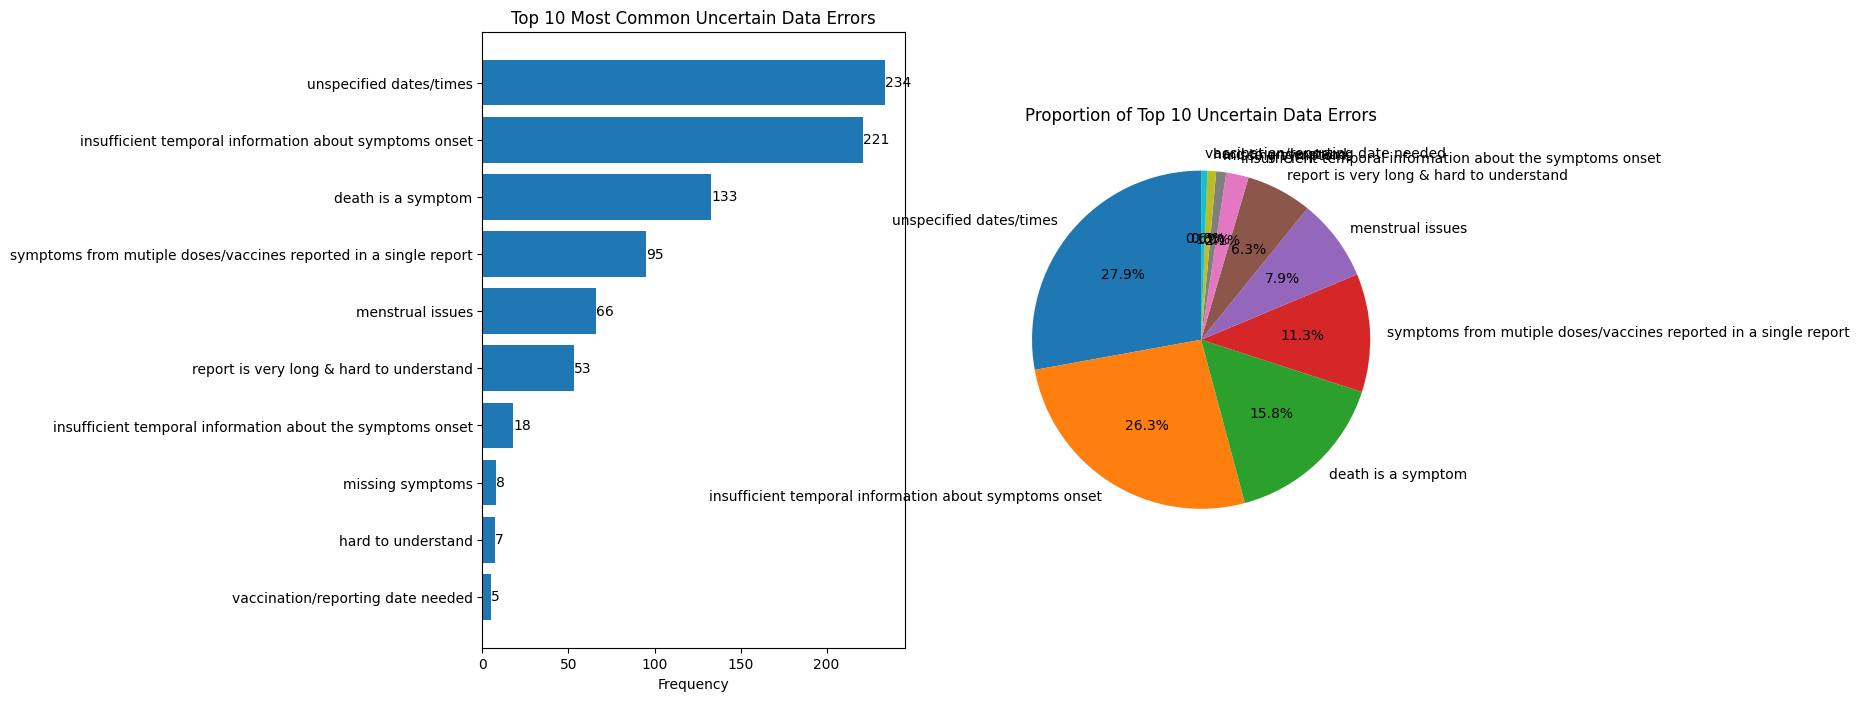

In [33]:
uncertain_data_errors = get_data_issues(uncertain_records)
plot_top(uncertain_data_errors, 'Uncertain Data Errors')

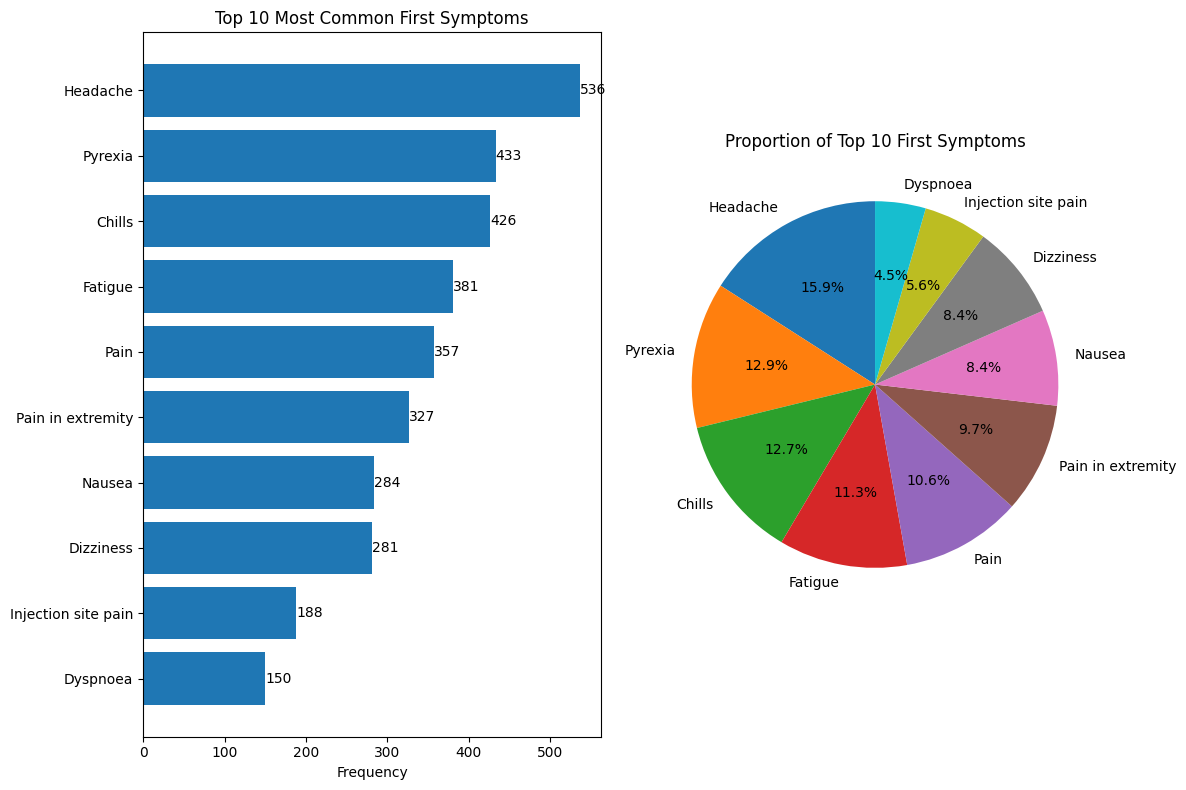

In [34]:
first_group_symptoms = get_symptoms_count(data_to_analyze, index=0)
plot_top(first_group_symptoms, text='First Symptoms')

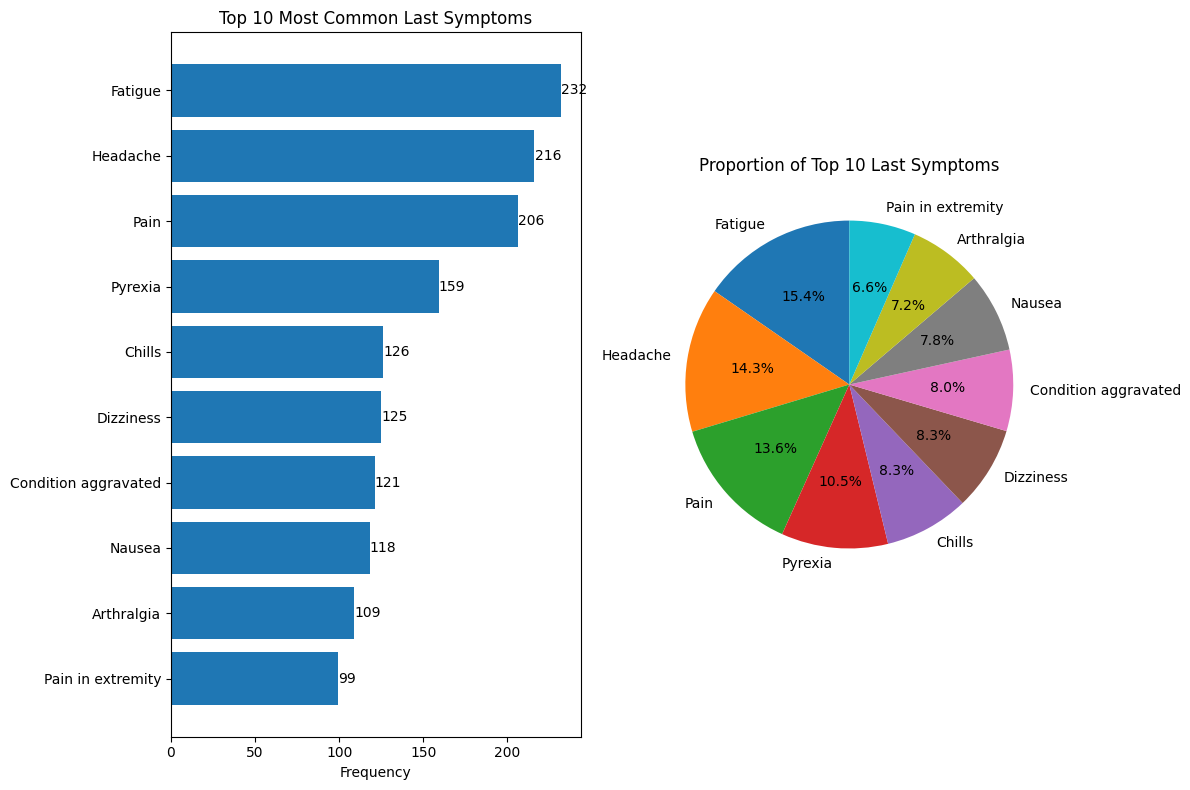

In [35]:
last_group_symptoms = get_symptoms_count(data_to_analyze, index=-1)
plot_top(last_group_symptoms, text='Last Symptoms')

1045950 invalid syntax (<unknown>, line 1) No temporal information found [
  {
    "Axillary mass": [
      "a large lump (axillary area) in the armpit of my left arm"
    ]
  },
  {
    "Injection site erythema": [
      "red welt"
    ],
    "Injection site induration": [
      "a hard area"
    ],
    "Injection site pruritus": [
      "aggressive itching at the injection site"
    ],
    "Injection site urticaria": [
      "red welt"
    ],
    "Lymph node pain": [
      "it is tender"
    ],
    "Musculoskeletal chest pain": [
      "tenderness on my chest above my right breast but on the pectoralis muscle"
    ],
    "Myalgia": [
      "tenderness on my chest above my right breast but on the pectoralis muscle"
    ]
  }
]
1415077 invalid syntax (<unknown>, line 1) No temporal information found [
  {
    "Headache": [
      "a headache and dizziness",
      "a squeezing, pressure-type headache that is affecting the top of his head and both sides of his forehead",
      "Had a head

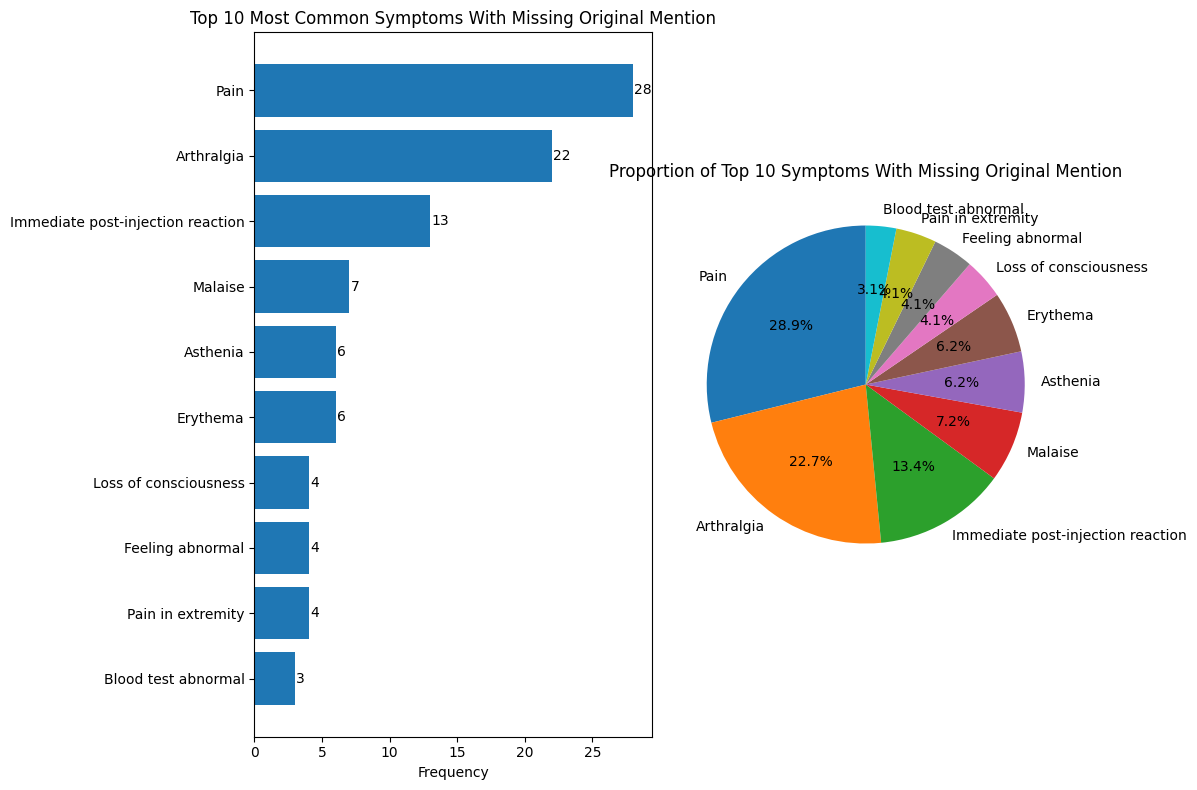

In [36]:
symptoms_with_missing_mention = get_symptoms_with_missing_original_mention(data_to_analyze)
plot_top(symptoms_with_missing_mention, text='Symptoms with Missing Original Mention')

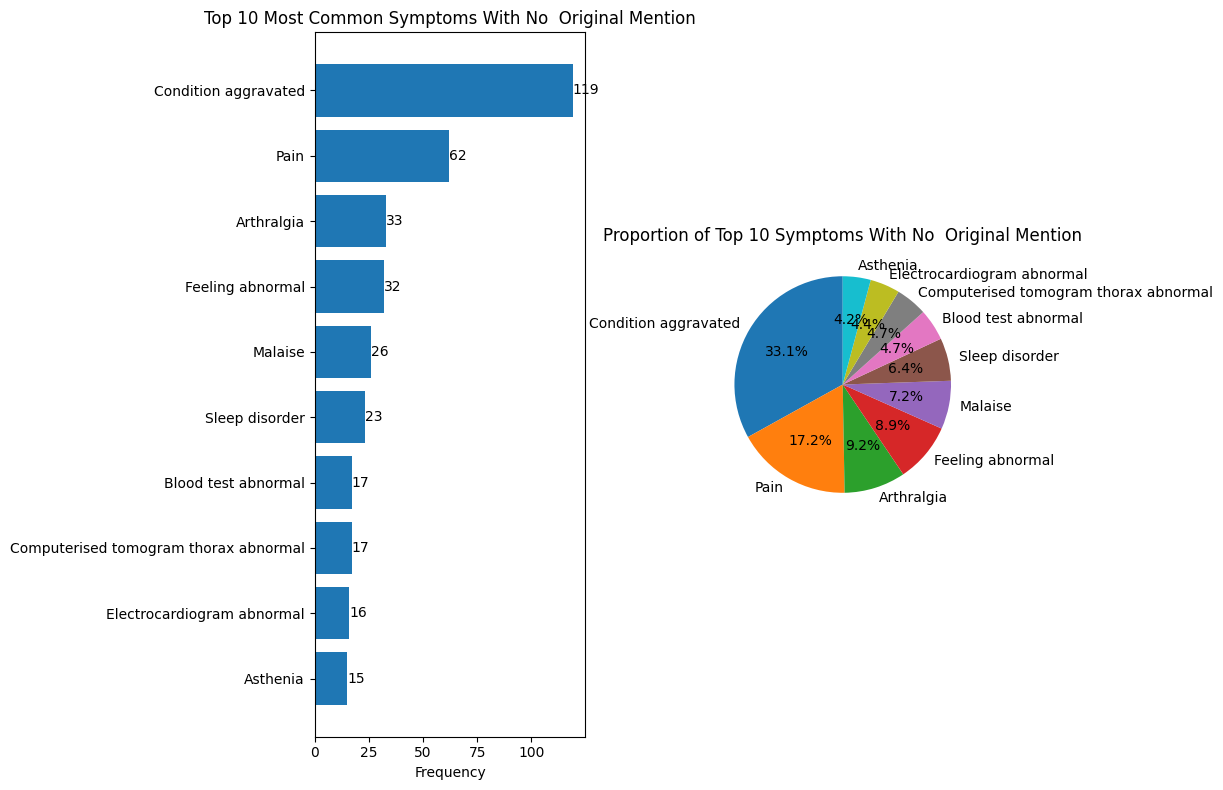

In [37]:
symptoms_with_no_mention = get_symptoms_with_no_original_mention(data_to_analyze)
plot_top(symptoms_with_no_mention, text='Symptoms With No  Original Mention')